In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from pathlib import Path
plt.rcParams['axes.spines.top'] = False
plt.rcParams['axes.spines.right'] = False
plt.rcParams['axes.spines.bottom'] = False
plt.rcParams['axes.spines.left'] = False
DATA_DIR = Path(r"C:\Users\david\OneDrive\Documenti\GitHub\Mathematical Models\WM Model\data")

## Get data from sheet

In [ ]:
df = pd.read_excel(DATA_DIR / "SpineDataFinal.xlsx")
df["Area"] = df["Area"].str.strip().str.upper()

grouped = df.groupby(["Area", "Metric", "Age"]).agg(     # For each area, metric and age, takes the mean of the values we have 
    mean=("Value", "mean"))                              # For now, we treat apical, basal and total dendrites as the same

pivot_mean = grouped["mean"].unstack("Age")              # We turn it into a "Area+Metric vs Age" table

# Compute % change for both metrics together
pct = pivot_mean.groupby(level="Metric").apply(
    lambda x: x.sub(x["Y"], axis=0).div(x["Y"], axis=0)
)

numb_pct = pct.groupby(level="Area").mean()


## Extrapolate

In [ ]:
area_spine = ['V1', 'V2', 'MT', 'LIP', 'V4', '7A' ,'7m', '8l', '8m', '5', 'TEO', 'DP', '2', 'F1', '7B', 'TEpd', '10', 'F5', '46d', 'PBr', '24c', 'F2', 'ProM', 'STPc', 'STPi', 'STPr', 'F7', '8b', '9/46v', '9/46d']

def mapping(areas = area_spine):
    area_map = {
        "V1": ["V1"],

        "7A": ["7A"],

        "ACC": ["24c"],

        "LPFC": [
            "46d",
            "9/46v"
        ],

        "dlPFC": [
            "9/46d",
            '10'
        ]
    }

    reverse_map = {
        v: k
        for k, lst in area_map.items()
        for v in lst
    }


    numb_dict = numb_pct.to_dict(orient="index")

    Extrapolate = {}

    for area in areas:
        region = reverse_map.get(area, area)
        numb = numb_dict.get(region, { 'A': np.nan, 'M': np.nan, 'Y': np.nan })
        Extrapolate[area] = numb
        
    return Extrapolate

    # print(Extrapolate.keys())
Extr = mapping()
# Extr

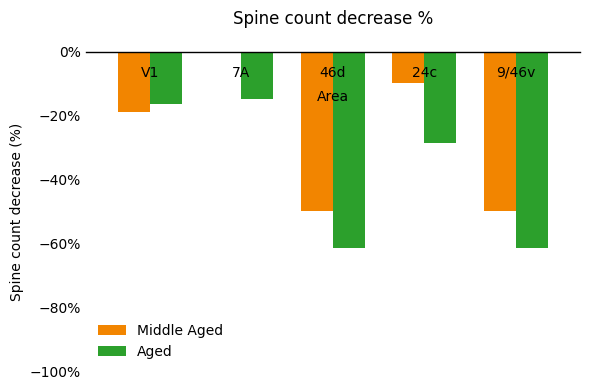

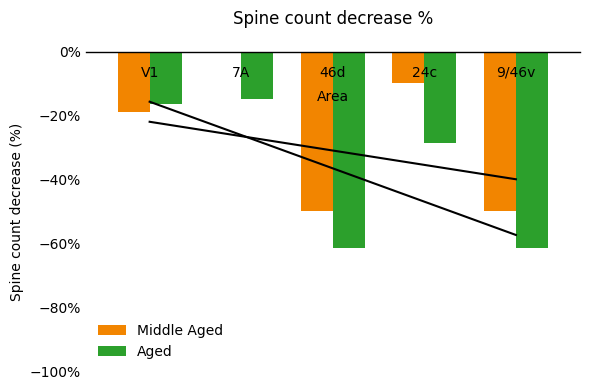

Average slope M: -4.495, Average Intercept M: -21.892
Average slope A: -10.419, Average Intercept A: -15.621


In [18]:
from matplotlib.ticker import PercentFormatter

def plots(Extrapolate, lines=False):
    width = 0.35
    area_names = []
    fig, ax = plt.subplots(figsize=(6, 4))
    cols = ['tab:blue', 'tab:orange', 'tab:green']
    offsets = [-0.5 * width, 0.5 * width]

    avg_slope_A, avg_int_A = [], []
    avg_slope_M, avg_int_M = [], []

    numb_data = np.zeros((30, 3))
    valid_mask = np.zeros(30, dtype=bool)
    for area, i in zip(Extrapolate.keys(), range(30)):
        temp = Extrapolate[area]
        if np.isnan(temp['M']) and np.isnan(temp['A']):
            continue
        numb_data[i, 0] = temp['Y'] * 100
        numb_data[i, 1] = temp['M'] * 100
        numb_data[i, 2] = temp['A'] * 100
        area_names.append(area)
        valid_mask[i] = True

    x = np.arange(len(area_names))
    numb_data = -np.abs(numb_data[valid_mask])

    ax.bar(x + offsets[0], numb_data[:, 1], width, color='#F28500', label='Middle Aged')
    ax.bar(x + offsets[1], numb_data[:, 2], width, color='#2CA02C', label='Aged')

    if lines:
        for i in range(1, numb_data.shape[1]):
            y = numb_data[:, i]
            mask = ~np.isnan(y)
            x_clean, y_clean = x[mask], y[mask]
            if x_clean.shape[0] != 1:
                slope, intercept = np.polyfit(x_clean, y_clean, 1)
                if i == 1:
                    avg_slope_M.append(slope); avg_int_M.append(intercept)
                elif i == 2:
                    avg_slope_A.append(slope); avg_int_A.append(intercept)
                ax.plot(x_clean, slope * x_clean + intercept, color='k')

    # x axis: labels just below the zero line, inside the plot, no ticks
    ax.set_xticks(x)
    ax.set_xticklabels(area_names)
    ax.xaxis.tick_top()
    ax.tick_params(axis='x', length=0, pad=-20)   # more negative = lower
    ax.text(0.5, 0.88, 'Area', transform=ax.transAxes, ha='center', va='top')

    # y axis
    ax.set_ylim(-100, 0)
    ax.yaxis.set_major_formatter(PercentFormatter(decimals=0))
    ax.tick_params(axis='y', length=0)
    ax.set_ylabel('Spine count decrease (%)')

    # spines: only the top (zero) line stays
    for s in ['bottom', 'left', 'right']:
        ax.spines[s].set_visible(False)
    ax.spines['top'].set_color('k')

    ax.set_xlim(x[0] - 0.7, x[-1] + 0.7)
    ax.set_title('Spine count decrease %', pad=20)
    ax.legend(loc='lower left', frameon=False)
    plt.tight_layout()
    ax.axhline(0, color='k', linewidth=1, zorder=3, clip_on=False)
    plt.savefig(f'../Fig/Aging plots/Spine count decrease {lines}.svg', dpi=150, bbox_inches='tight')
    plt.show()

    if lines:
        print(f"Average slope M: {np.mean(avg_slope_M):.3f}, Average Intercept M: {np.mean(avg_int_M):.3f}")
        print(f"Average slope A: {np.mean(avg_slope_A):.3f}, Average Intercept A: {np.mean(avg_int_A):.3f}")
    # hide all spines, draw the 0% line explicitly

Extr = mapping(areas = area_spine)
plots(Extr)
plots(Extr, lines=True)

# Aging factors

In [ ]:
labels = np.array(["Y", "MA", "A"])

# mask = (
#     df["Study"].str.strip().eq("Medalla & Luebke 2015") &
#     df["Area"].str.strip().str.upper().eq("V1")
# )

# df.loc[mask, "Value"] *= 1.1   # example adjustment

# factors to Y
to_Y = np.array([1.0, 1.15, 1.3])

# scaling matrix
scaling = to_Y[:, None] / to_Y[None, :]

# build full table with labels as first row and column
table = np.empty((len(labels) + 1, len(labels) + 1), dtype=object)

table[0, 0] = ""
table[0, 1:] = labels
table[1:, 0] = labels
table[1:, 1:] = scaling

# print(table)
print("\t" + "\t".join(labels))
for i, row in enumerate(scaling):
    print(labels[i] + "\t" + "\t".join(f"{x:.3f}" for x in row))
print(f"To go from 'row' i to 'column' j, we multiply by entry ij ")